# Mandatory assignment 3

**GitHub repository:** https://github.com/hflaten/tech2-HTFassignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


file = 'SCF_10pct.csv'

df = pd.read_csv(file)

# 1.1
for column in df.columns:
    print(f'Column name: "{column}". Number of non-missing values: {df[column].notna().sum()}')
print('\n')

# 1.2
for column in df.columns:
    n_missing_values = df[column].isna().sum()
    print(f'{n_missing_values} observations with value NaN in column "{column}".' , end=' ')
    if n_missing_values > 0:
        print('Observations dropped.', end='')
    print('\n')
observations_before_dropna = len(df)
df = df.dropna()
observations_after_dropna = len(df)
print(f'Remaining observations after dropping observations with missing values: ({observations_after_dropna})')

# 1.3
print('\n')
observations_before_age_condition = len(df)
df = df[(df['age'] >= 25) & (df['age'] <= 89)]
observations_after_age_condition = len(df)
print(f'Observations dropped when applying age condition: {observations_before_age_condition-observations_after_age_condition}')
print(f'Remaining observations after age condition applied: {observations_after_age_condition}')

# 1.4 
# create two series from conditions given in spec and add to df
direct_series = (df['stocks'] > 0).astype(int)
overall_series = (df['equity'] > 0).astype(int)
df['direct'] = direct_series
df['overall'] = overall_series



Column name: "id". Number of non-missing values: 5808
Column name: "year". Number of non-missing values: 5808
Column name: "age". Number of non-missing values: 5808
Column name: "educ". Number of non-missing values: 5792
Column name: "stocks". Number of non-missing values: 5790
Column name: "equity". Number of non-missing values: 5792


0 observations with value NaN in column "id". 

0 observations with value NaN in column "year". 

0 observations with value NaN in column "age". 

16 observations with value NaN in column "educ". Observations dropped.

18 observations with value NaN in column "stocks". Observations dropped.

16 observations with value NaN in column "equity". Observations dropped.

Remaining observations after dropping observations with missing values: (5758)


Observations dropped when applying age condition: 326
Remaining observations after age condition applied: 5432


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [ ]:
# 2.1
def participation_rate(indicator):
    count = 0
    for observation in indicator:
        if observation == 1:
            count += 1
    return f'{count/len(indicator)*100:.2f}%'

# 2.2
direct_participation_rate = participation_rate(df['direct'])
overall_partcipation_rate = participation_rate(df['overall'])

print(f'''Results from 2.1 (loop-approach):
Direct participation rate in final sample: {direct_participation_rate}.
Overall participation rate in final sample: {overall_partcipation_rate}.''')

# 2.3
direct_participation_rate_pdmean = (df['direct'].mean())
overall_participation_rate_pdmean = (df['overall'].mean())

print(f'''\nResults from 2.3 (built-in mean method):
Direct participation rate in final sample: {direct_participation_rate_pdmean*100:.2f}%.
Overall participation rate in final sample: {overall_participation_rate_pdmean*100:.2f}%.''')




Results from 2.1 (loop-approach):
Direct participation rate in final sample: 16.96%.
Overall participation rate in final sample: 49.41%.

Results from 2.3 (built-in mean method):
Direct participation rate in final sample: 16.96%.
Overall participation rate in final sample: 49.41%.


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

Participation rate for education category 1: direct rate: 4.4%, overall rate: 17.3%.
Participation rate for education category 2: direct rate: 11.4%, overall rate: 39.9%.
Participation rate for education category 3: direct rate: 13.5%, overall rate: 48.3%.
Participation rate for education category 4: direct rate: 30.5%, overall rate: 73.5%.

For both direct and overall participation rate, the rate increases for every increase in education level.
Overall participation rate is generally much higher than direct participation rate for all education levels.


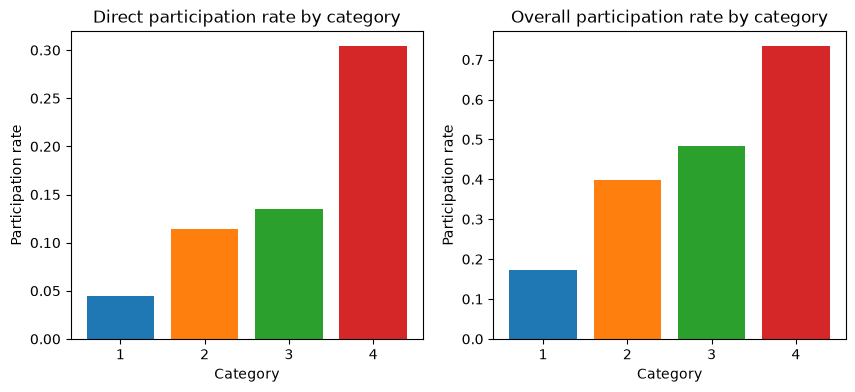

In [ ]:
# 3.3 , OO approach for plotting
figure, axes = plt.subplots(1,2, figsize = (10,4))

# 3.1 loop over categories and compute rate
for category in range(1,5):
    category_direct_participation_rate = df.loc[df['educ'] == category, 'direct'].mean()
    category_overall_participation_rate = df.loc[df['educ'] == category, 'overall'].mean()
    # 3.2
    print(
        f'Participation rate for education category {category}: '
        f'direct rate: {category_direct_participation_rate*100:.1f}%, '
        f'overall rate: {category_overall_participation_rate*100:.1f}%.'
        )

    # 3.3 plot rates to subplots
    axes[0].bar(category, category_direct_participation_rate)
    axes[0].set_title('Direct participation rate by category')
    axes[0].set_xlabel('Category')
    axes[0].set_ylabel('Participation rate')
    axes[1].bar(category, category_overall_participation_rate)
    axes[1].set_title('Overall participation rate by category')
    axes[1].set_xlabel('Category')
    axes[1].set_ylabel('Participation rate')

# part 3.4
print(f'''\nFor both direct and overall participation rate, the rate increases for every increase in education level.
Overall participation rate is generally much higher than direct participation rate for all education levels.''')
    

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

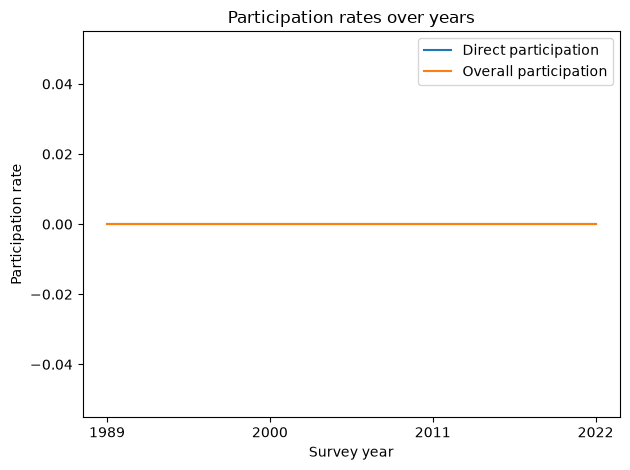

In [142]:


# remove duplicate years to have an iterable list of survey years
unique_years = df['year'].drop_duplicates()

yvalues_direct_rate = np.arange(len(unique_years))
yvalues_overall_rate = np.arange(len(unique_years))

# 4.1 loop over years and compute rate
for i, year in enumerate(unique_years):
    yearly_direct_participation_rate = df.loc[df['year'] == year, 'direct'].mean()
    yearly_overall_participation_rate = df.loc[df['year'] == year, 'overall'].mean()

    # store results
    yvalues_direct_rate[i] = yearly_direct_participation_rate
    yvalues_overall_rate[i] = yearly_overall_participation_rate
    i+=1

# 4.2 plot rates to subplots
ticks = list(range(1989, 2023, 11))

plt.plot(unique_years, yvalues_direct_rate, label="Direct participation")
plt.plot(unique_years, yvalues_overall_rate, label="Overall participation")

plt.title("Participation rates over years")
plt.xlabel("Survey year")
plt.ylabel("Participation rate")
plt.xticks(ticks)
plt.legend()
plt.tight_layout()
plt.show()

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.